# Práctica 3 — Redes convolucionales (CNN) sobre MNIST
**Autor:** Jorge Sebastián Cortés Ocaña

Se clasifican los **10 dígitos** de MNIST con redes convolucionales. Partimos de una CNN mínima y se añaden o cambian las capas vistas en clase **de una en una** (segunda convolución, Dropout, BatchNormalization y tipo de *pooling*). Se usan redes pequeñas para que el entrenamiento sea rápido.

El mejor modelo se elige con un **conjunto de validación** y el test solo se usa para medir el resultado final.

In [1]:
import tensorflow as tf
import time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

SEMILLA = 42
L = tf.keras.layers
print(tf.__version__)

2.21.0


## 1. Datos
- Se normalizan los píxeles a [0, 1] y se añade la dimensión de **canal**: las capas `Conv2D` esperan imágenes de forma `(alto, ancho, canales)`, en este caso `(28, 28, 1)` (escala de grises).
- **Validación:** se separan las últimas 6.000 imágenes de entrenamiento.

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = (x_train / 255.0)[..., np.newaxis].astype('float32')     # (60000, 28, 28, 1)
x_test  = (x_test  / 255.0)[..., np.newaxis].astype('float32')

N_VAL = 6000
x_tr, x_val = x_train[:-N_VAL], x_train[-N_VAL:]
y_tr, y_val = y_train[:-N_VAL], y_train[-N_VAL:]
print(f"Train: {x_tr.shape} | Val: {x_val.shape} | Test: {x_test.shape}")

Train: (54000, 28, 28, 1) | Val: (6000, 28, 28, 1) | Test: (10000, 28, 28, 1)


## 2. Capas utilizadas y metodología

| Capa | Qué hace |
| :-- | :-- |
| `Conv2D(n, k)` | Aplica `n` filtros de `k×k` que detectan patrones locales (bordes, trazos). Se usa `padding='same'` y ReLU. |
| `MaxPooling2D` / `AveragePooling2D` | Reducen a la mitad el alto y el ancho quedándose con el máximo o la media de cada ventana 2×2. |
| `BatchNormalization` | Normaliza la salida de la capa en cada lote; estabiliza y acelera el entrenamiento. |
| `Dropout(p)` | Apaga al azar un `p` de las neuronas al entrenar para reducir el sobreajuste. |
| `Flatten` + `Dense` | Aplanan los mapas de características y los clasifican con una capa totalmente conectada. |

**Entrenamiento común a todas:** Adam, lote 128, salida `Dense(10, softmax)` con `sparse_categorical_crossentropy`, 5 épocas (como en la P1) y la misma semilla para todas.

Las arquitecturas se describen con una lista de capas, por ejemplo `['conv16', 'maxpool', 'flatten', 'dense64']`. La capa de salida se añade siempre al final.

In [3]:
def capa(token):
    if token.startswith('conv'):  return L.Conv2D(int(token[4:]), 3, padding='same', activation='relu')
    if token.startswith('dense'): return L.Dense(int(token[5:]), activation='relu')
    if token.startswith('drop'):  return L.Dropout(float(token[4:]))
    if token == 'maxpool': return L.MaxPooling2D(pool_size=2)
    if token == 'avgpool': return L.AveragePooling2D(pool_size=2)
    return {'bn': L.BatchNormalization, 'flatten': L.Flatten}[token]()

def crear_modelo(capas):
    return tf.keras.Sequential([tf.keras.Input(shape=(28, 28, 1))] + [capa(t) for t in capas]
                               + [L.Dense(10, activation='softmax')])

def entrenar(capas, semilla=SEMILLA):
    tf.keras.utils.set_random_seed(semilla)
    modelo = crear_modelo(capas)
    modelo.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    h = modelo.fit(x_tr, y_tr, validation_data=(x_val, y_val), epochs=5, batch_size=128, verbose=0)
    t = time.time() - t0
    acc = [modelo.evaluate(x, y, verbose=0, batch_size=1024)[1]
           for x, y in [(x_tr, y_tr), (x_val, y_val), (x_test, y_test)]]
    return modelo, h.history, t, acc

## 3. Configuraciones
La referencia es el **MLP de la P1** (sin convoluciones). Cada CNN cambia **un solo aspecto** respecto a la indicada en la columna *Compara con*.

| Config | Capas (antes de la salida) | Compara con | Qué se estudia |
| :-- | :-- | :-- | :-- |
| MLP | Flatten → Dense 64 | – | Referencia: red densa sin convoluciones |
| CNN1 | Conv16 → MaxPool → Flatten → Dense 64 | MLP | Efecto de añadir una convolución |
| CNN2 | Conv16 → MaxPool → Conv32 → MaxPool → Flatten → Dense 64 | CNN1 | Un segundo bloque convolucional |
| CNN2_drop | CNN2 + Dropout 0.25 tras cada bloque | CNN2 | Regularización con Dropout |
| CNN2_bn | CNN2_drop + BatchNorm tras cada Conv | CNN2_drop | BatchNormalization |
| CNN2_avg | CNN2_drop con AveragePooling | CNN2_drop | Tipo de pooling |

In [4]:
CONFIGS = {
    'MLP':       ['flatten', 'dense64'],
    'CNN1':      ['conv16', 'maxpool', 'flatten', 'dense64'],
    'CNN2':      ['conv16', 'maxpool', 'conv32', 'maxpool', 'flatten', 'dense64'],
    'CNN2_drop': ['conv16', 'maxpool', 'drop0.25', 'conv32', 'maxpool', 'drop0.25', 'flatten', 'dense64'],
    'CNN2_bn':   ['conv16', 'bn', 'maxpool', 'drop0.25', 'conv32', 'bn', 'maxpool', 'drop0.25', 'flatten', 'dense64'],
    'CNN2_avg':  ['conv16', 'avgpool', 'drop0.25', 'conv32', 'avgpool', 'drop0.25', 'flatten', 'dense64'],
}

resultados, modelos, historiales = [], {}, {}
for nombre, capas in CONFIGS.items():
    modelo, hist, t, acc = entrenar(capas)
    modelos[nombre], historiales[nombre] = modelo, hist
    resultados.append({'Config': nombre, 'Parámetros': modelo.count_params(), 'Tiempo (s)': round(t, 1),
                       'Acc Train': acc[0], 'Acc Val': acc[1], 'Acc Test': acc[2],
                       'Errores Val': round((1 - acc[1]) * len(y_val)),
                       'Errores Test': round((1 - acc[2]) * len(y_test))})
    print(f"{nombre:10s} {t:6.1f} s | Train {acc[0]:.4f} | Val {acc[1]:.4f} | Test {acc[2]:.4f}")

MLP           7.6 s | Train 0.9711 | Val 0.9695 | Test 0.9628


CNN1         41.3 s | Train 0.9894 | Val 0.9842 | Test 0.9819


CNN2         42.8 s | Train 0.9919 | Val 0.9878 | Test 0.9873


CNN2_drop    51.0 s | Train 0.9910 | Val 0.9888 | Test 0.9885


CNN2_bn      96.2 s | Train 0.9924 | Val 0.9892 | Test 0.9868


CNN2_avg     61.5 s | Train 0.9865 | Val 0.9858 | Test 0.9860


## 4. Comparativa numérica
Tabla ordenada por exactitud en **validación**, que es el criterio de selección. *Train − Val* mide el sobreajuste. En validación hay 6.000 imágenes, así que una diferencia de 0,001 equivale a solo 6 aciertos.

In [5]:
res = pd.DataFrame(resultados)
res['Train−Val'] = res['Acc Train'] - res['Acc Val']
res = res.sort_values('Acc Val', ascending=False)
res.style.format({'Acc Train': '{:.4f}', 'Acc Val': '{:.4f}', 'Acc Test': '{:.4f}', 'Train−Val': '{:+.4f}',
                  'Parámetros': '{:,}'}) \
   .highlight_max(subset=['Acc Val'], color='#c6efce').hide(axis='index')

Config,Parámetros,Tiempo (s),Acc Train,Acc Val,Acc Test,Errores Val,Errores Test,Train−Val
CNN2_bn,"106,058",96.200000,0.9924,0.9892,0.9868,65,132,+0.0032
CNN2_drop,"105,866",51.000000,0.9910,0.9888,0.9885,67,115,+0.0021
CNN2,"105,866",42.800000,0.9919,0.9878,0.9873,73,127,+0.0041
CNN2_avg,"105,866",61.500000,0.9865,0.9858,0.9860,85,140,+0.0007
CNN1,"201,578",41.300000,0.9894,0.9842,0.9819,95,181,+0.0053
MLP,"50,890",7.600000,0.9711,0.9695,0.9628,183,372,+0.0016


## 5. Comparativa gráfica

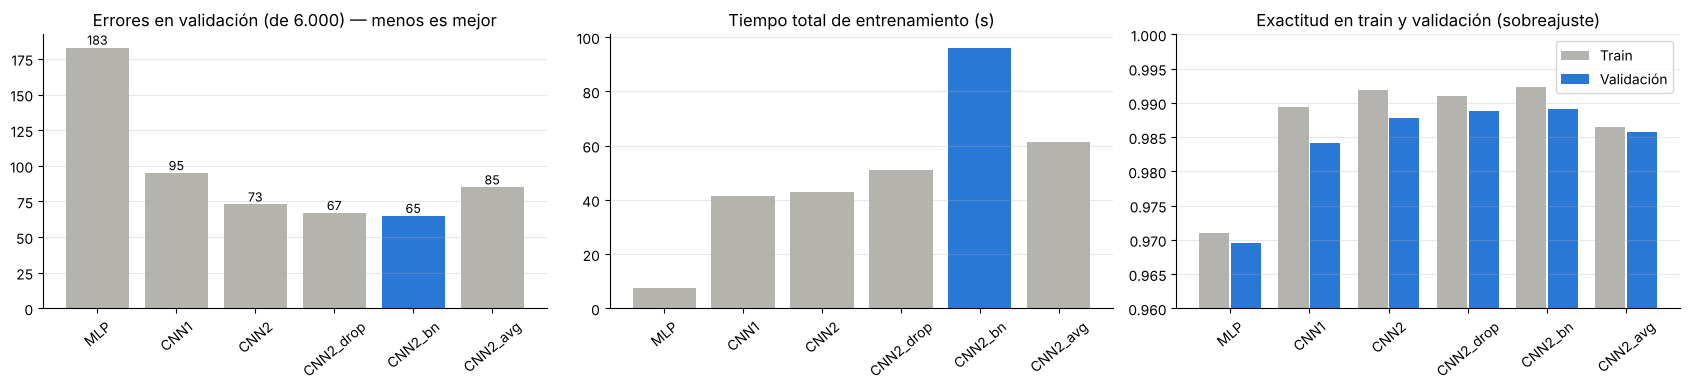

In [6]:
AZUL, GRIS, NARANJA, VERDE = '#2a78d6', '#b5b3ad', '#eb6834', '#1baf7a'
d = pd.DataFrame(resultados)
mejor_val = d.loc[d['Acc Val'].idxmax(), 'Config']
col = [AZUL if c == mejor_val else GRIS for c in d['Config']]

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].bar(d['Config'], d['Errores Val'], color=col)
for i, v in enumerate(d['Errores Val']): ax[0].text(i, v + 2, v, ha='center', fontsize=9)
ax[0].set_title('Errores en validación (de 6.000) — menos es mejor')
ax[1].bar(d['Config'], d['Tiempo (s)'], color=col)
ax[1].set_title('Tiempo total de entrenamiento (s)')
x = np.arange(len(d))
ax[2].bar(x - 0.2, d['Acc Train'], 0.38, color=GRIS, label='Train')
ax[2].bar(x + 0.2, d['Acc Val'], 0.38, color=AZUL, label='Validación')
ax[2].set_xticks(x, d['Config']); ax[2].set_ylim(0.96, 1.0); ax[2].legend()
ax[2].set_title('Exactitud en train y validación (sobreajuste)')
for a in ax: a.tick_params(axis='x', rotation=40)
for a in ax:
    a.grid(axis='y', alpha=0.3); a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

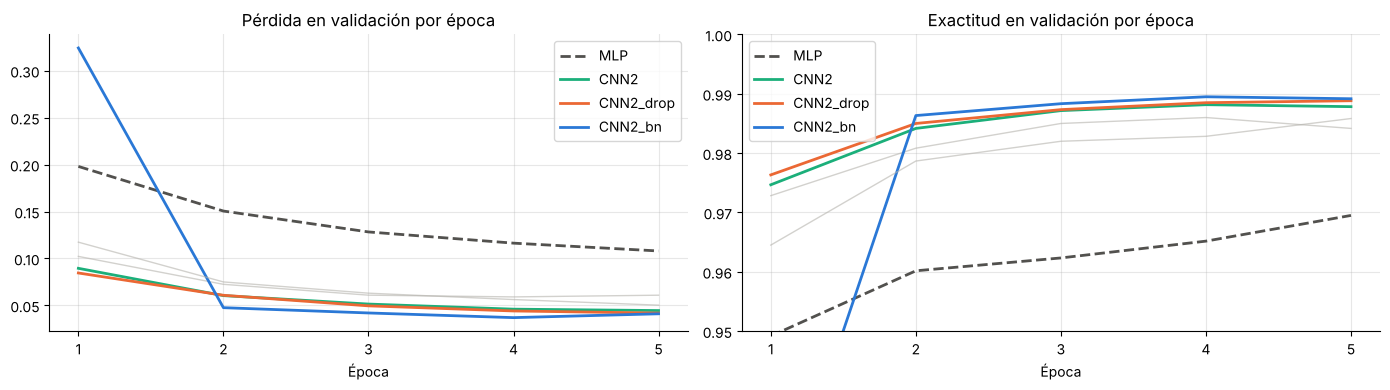

In [7]:
# Curvas de validación: se resaltan las 3 mejores y el MLP de referencia
top3 = list(res['Config'][:3])
colores = dict(zip(top3, [AZUL, NARANJA, VERDE]))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for nombre, h in historiales.items():
    destacada = nombre in top3 or nombre == 'MLP'
    c = colores.get(nombre, '#52514e' if nombre == 'MLP' else GRIS)
    ep = range(1, len(h['val_loss']) + 1)
    kw = dict(color=c, lw=2 if destacada else 1, alpha=1 if destacada else 0.6,
              ls='--' if nombre == 'MLP' else '-', label=nombre if destacada else None)
    ax[0].plot(ep, h['val_loss'], **kw); ax[1].plot(ep, h['val_accuracy'], **kw)
ax[0].set_title('Pérdida en validación por época'); ax[1].set_title('Exactitud en validación por época')
ax[1].set_ylim(0.95, 1.0)
for a in ax:
    a.set_xlabel('Época'); a.set_xticks(range(1, 6)); a.grid(alpha=0.3); a.legend(); a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

### Conclusiones de la comparativa
- **Las convoluciones son lo que más mejora:** con una sola capa `Conv2D` (CNN1) los errores en validación bajan de 183 a 95 (−48 %) respecto a la red densa. Las convoluciones aprovechan la estructura 2D de la imagen, cosa que `Flatten` + `Dense` pierde.
- **El segundo bloque convolucional ayuda y además reduce parámetros:** CNN2 baja a 73 errores con la mitad de parámetros que CNN1 (106 mil frente a 202 mil). El segundo `MaxPooling` deja mapas de 7×7 en lugar de 14×14, así que la capa `Dense` posterior es mucho más pequeña.
- **Dropout reduce el sobreajuste:** de CNN2 a CNN2_drop la diferencia *Train − Val* se reduce a la mitad (0,0041 → 0,0021) y los errores pasan de 73 a 67.
- **BatchNormalization apenas cambia el resultado:** CNN2_bn es la mejor en validación (65 errores), pero solo 2 imágenes por delante de CNN2_drop, una diferencia que puede deberse al azar. Además, en esta ejecución (en CPU) tarda casi el doble. En la primera época su validación es muy mala (pérdida mayor de 0,3) y desde la segunda se pone por delante del resto.
- **MaxPooling funciona mejor que AveragePooling** (67 frente a 85 errores). El máximo conserva el trazo más marcado de cada ventana, mientras que la media lo diluye con el fondo. AveragePooling es la que menos sobreajusta, pero porque también aprende menos en entrenamiento.
- **Tiempo:** el tiempo medido varía bastante entre ejecuciones, así que solo se tienen en cuenta las diferencias grandes, como la de BatchNorm o la del MLP frente a las CNN.

## 6. Análisis de errores del mejor modelo (test)

Mejor configuración: CNN2_bn ['conv16', 'bn', 'maxpool', 'drop0.25', 'conv32', 'bn', 'maxpool', 'drop0.25', 'flatten', 'dense64']


CNN2_bn: exactitud en test 0.9868 | 132 errores de 10.000


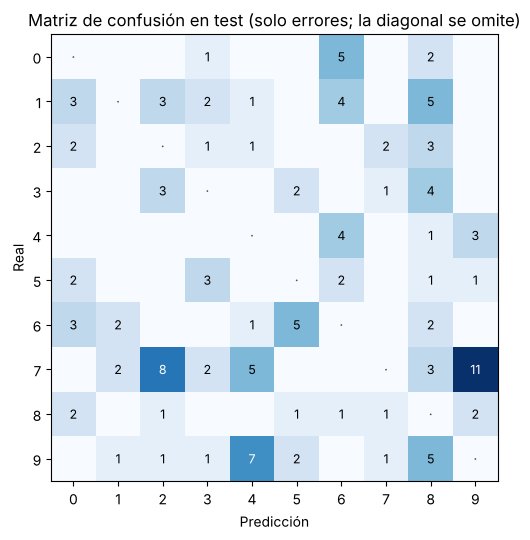

Confusiones más frecuentes: 7→9 (11), 7→2 (8), 9→4 (7)


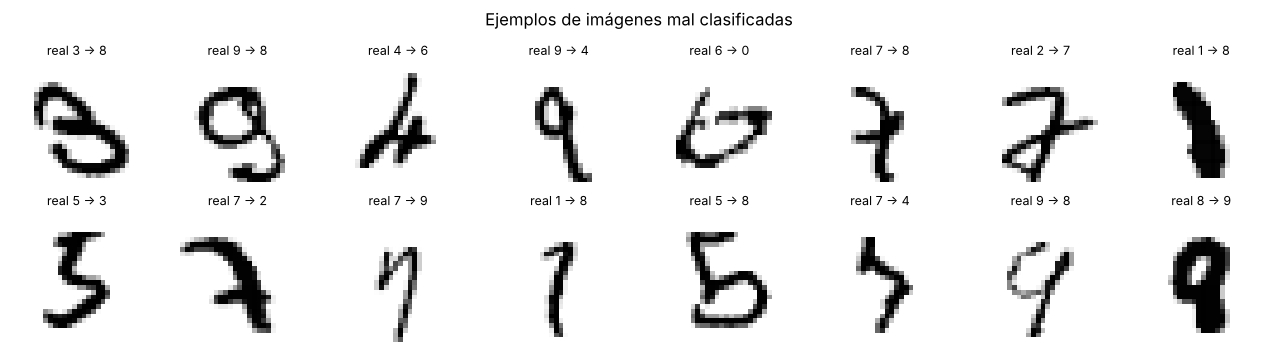

In [8]:
mejor = res.iloc[0]['Config']                    # la mejor en validación
print('Mejor configuración:', mejor, CONFIGS[mejor])
modelo_final = modelos[mejor]
pred = np.argmax(modelo_final.predict(x_test, verbose=0, batch_size=1024), axis=1)
fallos = np.where(pred != y_test)[0]
print(f"{mejor}: exactitud en test {np.mean(pred == y_test):.4f} | {len(fallos)} errores de 10.000")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
cm = confusion_matrix(y_test, pred)
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
ax.imshow(cm_off, cmap='Blues')
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j]: ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=9,
                                        color='white' if cm[i, j] > cm_off.max() / 2 else 'black')
        if i == j: ax.text(j, i, '·', ha='center', va='center', color='#52514e')
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
ax.set_title('Matriz de confusión en test (solo errores; la diagonal se omite)')
plt.tight_layout(); plt.show()

pares = sorted(((cm_off[i, j], i, j) for i in range(10) for j in range(10)), reverse=True)[:3]
print('Confusiones más frecuentes:', ', '.join(f'{i}→{j} ({n})' for n, i, j in pares))

fig, ax = plt.subplots(2, 8, figsize=(13, 3.6))
for a, k in zip(ax.flat, fallos[:16]):
    a.imshow(x_test[k, :, :, 0], cmap='gray_r'); a.axis('off')
    a.set_title(f'real {y_test[k]} → {pred[k]}', fontsize=9)
plt.suptitle('Ejemplos de imágenes mal clasificadas'); plt.tight_layout(); plt.show()

Con CNN2_bn hay 132 errores en test de 10.000. El dígito que más falla es el **7** (31 errores), que se confunde sobre todo con el 9 y el 2. Le siguen el 1 y el 9 (18 cada uno), y el 9 se toma a menudo por un 4. En los ejemplos se ve que muchos fallos son dígitos mal escritos o ambiguos incluso para una persona.

## 7. Guardado del mejor modelo
Formato nativo `.keras` (arquitectura, pesos y estado del optimizador) y un JSON con la configuración. Después se carga y se comprueba que da el mismo resultado.

In [10]:
modelo_final.save('mejor_cnn_mnist.keras')
with open('mejor_cnn_mnist.json', 'w', encoding='utf-8') as f:
    json.dump({'config': mejor, 'capas': CONFIGS[mejor]}, f)

# Uso futuro
cargado = tf.keras.models.load_model('mejor_cnn_mnist.keras')
_, acc_cargado = cargado.evaluate(x_test, y_test, verbose=0)
print(f"Exactitud en test del modelo cargado: {acc_cargado:.4f}")
print("Reales:     ", y_test[:10])
print("Predicciones:", np.argmax(cargado.predict(x_test[:10], verbose=0), axis=1))

Exactitud en test del modelo cargado: 0.9868
Reales:      [7 2 1 0 4 1 4 9 5 9]
Predicciones: [7 2 1 0 4 1 4 9 5 9]


## 8. Conclusión: ¿qué configuración obtiene el mejor rendimiento?
Siguiendo el criterio fijado (exactitud en validación), la mejor es **CNN2_bn**:

| Capas | Parámetros | Acc Val | Acc Test | Errores Test | Tiempo |
| :-- | :-- | :-- | :-- | :-- | :-- |
| Conv16 → BN → MaxPool → Dropout 0.25 → Conv32 → BN → MaxPool → Dropout 0.25 → Flatten → Dense 64 → Dense 10 | 106.058 | 0,9892 | **0,9868** | **132** | 96 s (CPU) |

Frente a la red densa sin convoluciones (372 errores en test), reduce los errores un **65 %**. Sus claves son las **dos capas convolucionales con MaxPooling** y la **regularización con Dropout**.

**Matiz:** CNN2_drop (la misma red sin BatchNorm) queda prácticamente empatada en validación (67 frente a 65 errores) y entrena en la mitad de tiempo. Con estos datos no se puede afirmar que BatchNorm aporte una mejora real. Para desempatarlas habría que repetir el entrenamiento con varias semillas y comparar la media. Si el tiempo de entrenamiento importa, CNN2_drop es igual de válida.

El modelo se ha guardado como `mejor_cnn_mnist.keras` junto con su configuración en `mejor_cnn_mnist.json`, y se ha comprobado que al cargarlo da la misma exactitud.